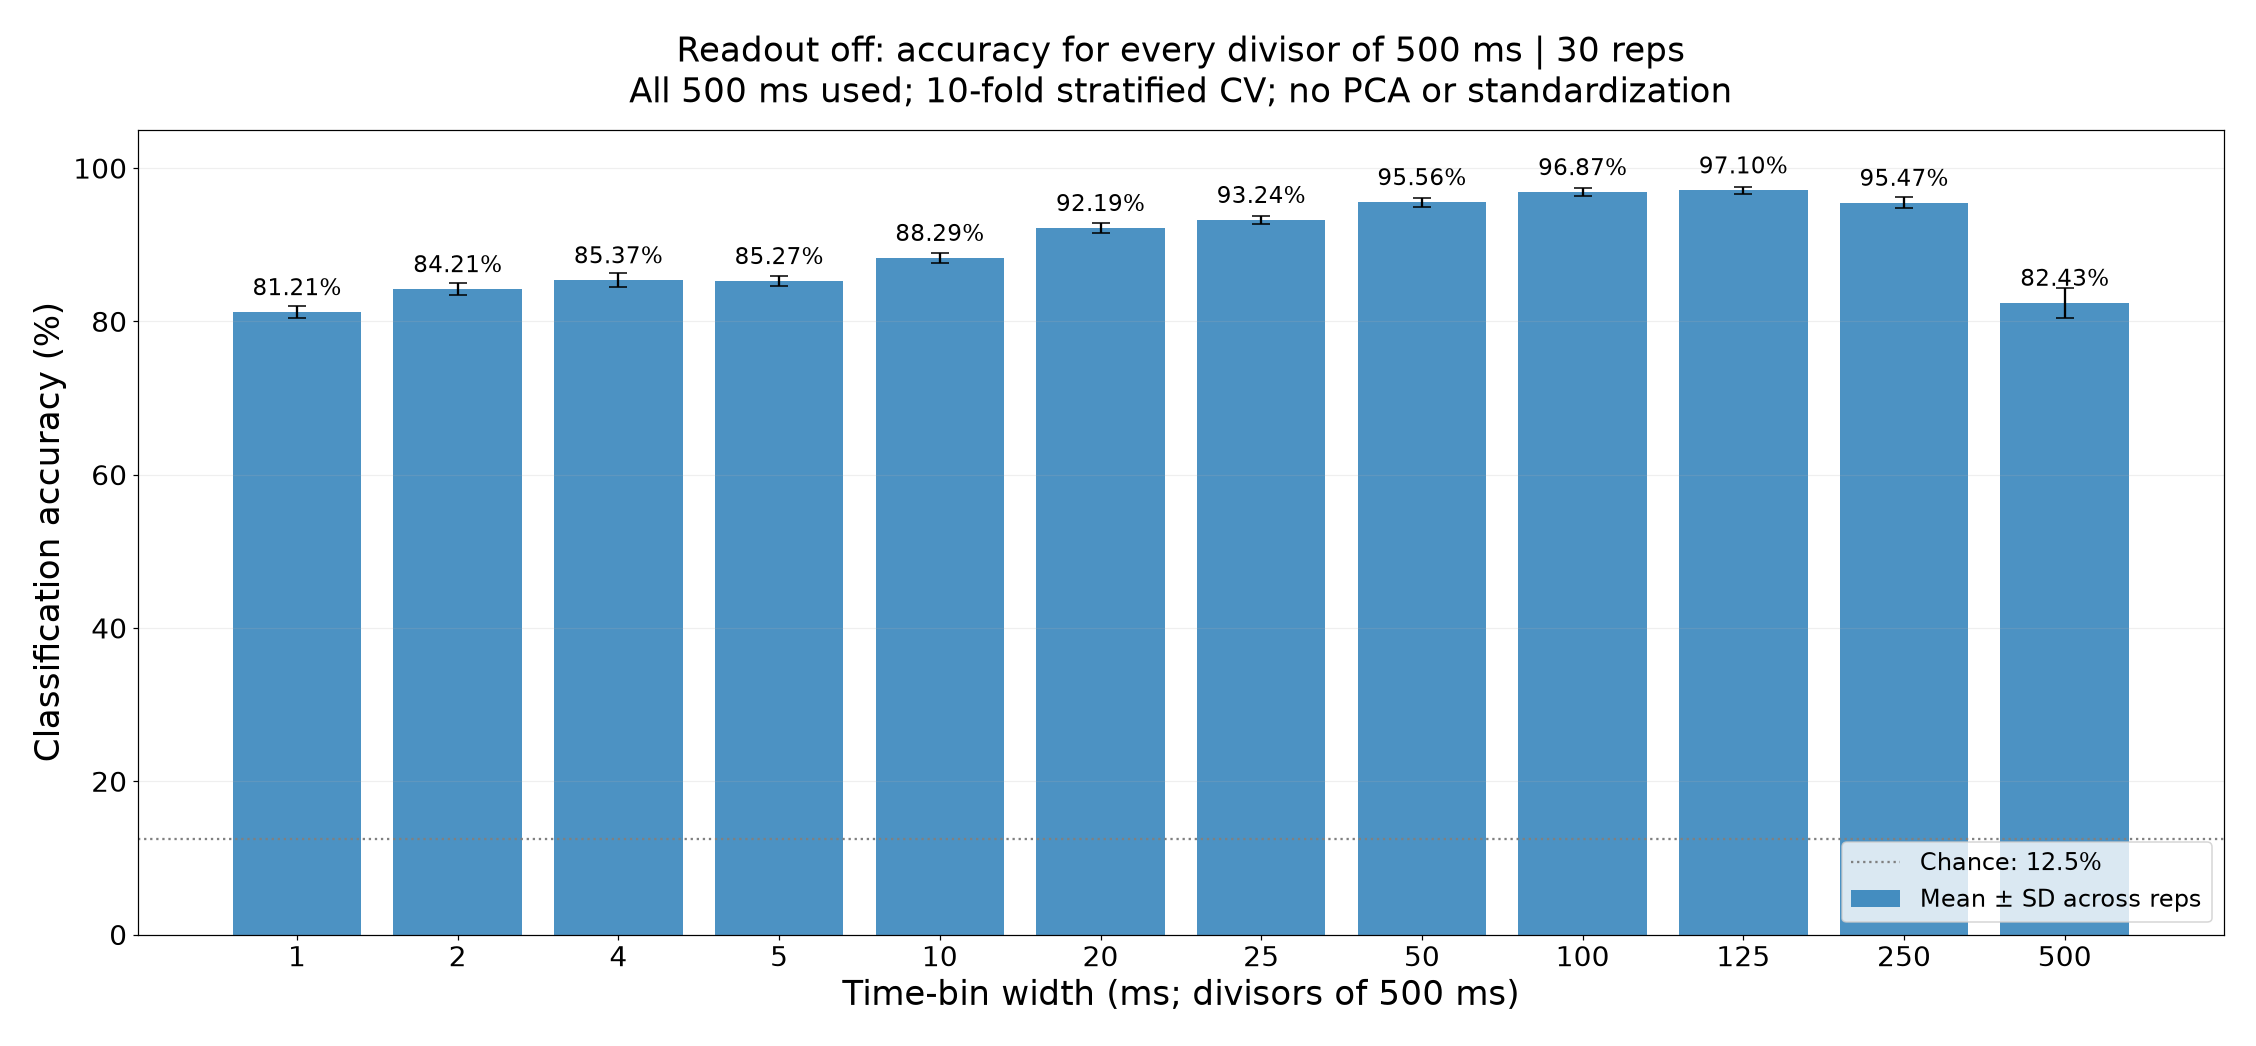

  1 ms × 500 bins: 81.213% ± 0.778%
  2 ms × 250 bins: 84.213% ± 0.825%
  4 ms × 125 bins: 85.371% ± 0.923%
  5 ms × 100 bins: 85.267% ± 0.673%
 10 ms ×  50 bins: 88.287% ± 0.708%
 20 ms ×  25 bins: 92.188% ± 0.681%
 25 ms ×  20 bins: 93.237% ± 0.488%
 50 ms ×  10 bins: 95.562% ± 0.599%
100 ms ×   5 bins: 96.871% ± 0.484%
125 ms ×   4 bins: 97.096% ± 0.459%
250 ms ×   2 bins: 95.475% ± 0.714%
500 ms ×   1 bins: 82.433% ± 1.977%


In [1]:
# Readout offの各repの混同行列を合算する（分類の再実行・結果ファイルの保存はしない）。
from pathlib import Path
from zipfile import ZipFile
from xml.etree import ElementTree as ET
import posixpath
import sys
import numpy as np
import matplotlib.pyplot as plt

# ノートブックをLSM直下・h_analysis・研究コード直下のいずれから開いても探す。
project_root = next(
    (root for parent in (Path.cwd(), *Path.cwd().parents)
     for root in (parent, parent / "LSM")
     if (root / "d_tools" / "evaluation_excel.py").is_file()), None
)
if project_root is None:
    raise FileNotFoundError("LSMフォルダからノートブックを開いてください。")
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
from d_tools.evaluation_excel import load_classification_results

# Noneなら保存済みの全repを使用。例：[1, 2, 3, 4, 5]で対象を限定できる。
REPS = None
BIN_MS = 25.0
# 結合確率・gainを指定し、この条件のoff結果だけを集計する。
CONNECTION_FOLDER = "p_E_readout-0.11__g_e_out-0.2706"
results_root = project_root / "g_tactile_results" / "readout_run" / CONNECTION_FOLDER / "off"


def read_confusion_counts(workbook_path, block_index):
    """指定した評価時間窓の8素材の個数を、Excelのconf_8clsシートから読む。"""
    ns = {"s": "http://schemas.openxmlformats.org/spreadsheetml/2006/main"}
    with ZipFile(workbook_path) as archive:
        workbook = ET.fromstring(archive.read("xl/workbook.xml"))
        sheet = next(s for s in workbook.findall("s:sheets/s:sheet", ns)
                     if s.get("name") == "conf_8cls")
        relations = {r.get("Id"): r.get("Target") for r in ET.fromstring(
            archive.read("xl/_rels/workbook.xml.rels"))}
        target = relations[sheet.get("{http://schemas.openxmlformats.org/officeDocument/2006/relationships}id")]
        target = target.lstrip("/") if target.startswith("/") else posixpath.normpath(posixpath.join("xl", target))
        cells = {c.get("r"): c for c in ET.fromstring(archive.read(target)).findall("s:sheetData/s:row/s:c", ns)}
        counts = np.array([[float(cells[f"{col}{row}"].find("s:v", ns).text)
                            for col in "BCDEFGHI"]
                           for row in range(2 + 12 * block_index, 10 + 12 * block_index)])
    if np.any(counts < 0) or not np.all(np.isfinite(counts)) or not np.all(counts == np.floor(counts)):
        raise ValueError(f"混同行列の個数が不正です：{workbook_path}")
    return counts.astype(np.int64)


# 同一の素材順・時間窓・分割数の結果だけを合算する。
rep_dirs = sorted((p for p in results_root.glob("rep*")
                   if p.is_dir() and p.name[3:].isdigit()), key=lambda p: int(p.name[3:]))
if REPS is not None:
    missing = set(REPS) - {int(p.name[3:]) for p in rep_dirs}
    if missing:
        raise FileNotFoundError(f"見つからないrep：{sorted(missing)}")
    rep_dirs = [p for p in rep_dirs if int(p.name[3:]) in REPS]
combined_counts = np.zeros((8, 8), dtype=np.int64)
used_reps, per_rep_accuracies = [], []
# 各repの行正規化割合を保持する。
per_rep_percentages = []
materials, folds = None, None
for rep_dir in rep_dirs:
    workbook_path = rep_dir / "test" / "eval" / "classification.xlsx"
    if not workbook_path.is_file():
        print(f"未完了のためスキップ：{rep_dir.name}")
        continue
    metadata = load_classification_results(workbook_path)
    if metadata is None:
        raise ValueError(f"評価条件を読み込めません：{workbook_path}")
    conditions = [i for i, value in enumerate(metadata["T_n_ms"])
                  if np.isclose(float(value), BIN_MS)]
    if len(conditions) != 1:
        raise ValueError(f"{rep_dir.name}に{BIN_MS:g} msの評価が一つだけ存在する必要があります。")
    if materials is None:
        materials, folds = metadata["materials"], metadata["folds"]
    if metadata["materials"] != materials or metadata["folds"] != folds:
        raise ValueError(f"素材順または分割数が異なります：{rep_dir.name}")
    counts = read_confusion_counts(workbook_path, conditions[0])
    if counts.sum() == 0 or np.any(counts.sum(axis=1) == 0):
        raise ValueError(f"評価個数が空です：{rep_dir.name}")
    accuracy = np.trace(counts) / counts.sum()
    summary = next(s for s in metadata["summary"] if np.isclose(float(s["T_n_ms"]), BIN_MS))
    if not np.isclose(accuracy, summary["accuracy"]):
        raise ValueError(f"個数と記録済み正答率が一致しません：{rep_dir.name}")
    per_rep_percentages.append(counts / counts.sum(axis=1, keepdims=True) * 100)
    combined_counts += counts
    used_reps.append(int(rep_dir.name[3:]))
    per_rep_accuracies.append(accuracy * 100)
if not used_reps:
    raise FileNotFoundError(f"集計できる評価結果がありません：{results_root}")

# 色は正解素材ごとの割合。各マスに合算個数と割合を併記する。
# 500 msのすべての整数約数を時間ビン幅にし、500 ms全体の分類精度を比較する。
# 時間区間を別々に分類するのではなく、全区間×全出力ニューロンを特徴量にする。
from concurrent.futures import ThreadPoolExecutor, as_completed
from sklearn.model_selection import StratifiedKFold
from threadpoolctl import threadpool_limits
from tqdm.auto import tqdm
from d_tools.evaluation import extract_features
from d_tools.classification import classify
from d_tools.recording_io import read_record

DURATION_MS = 500
BIN_WIDTHS_MS = [width for width in range(1, DURATION_MS + 1) if DURATION_MS % width == 0]
# repごとに並列化する。メモリが足りない場合は1または2にする。
BIN_EVAL_WORKERS = 4



def predict_large_feature_fold(features, labels, train, test, gram):
    """通常と同じ正則化Mahalanobis距離を、試行間の内積から計算する。

    高次元でのSVDの繰り返しを避ける。共分散の非零固有値と射影を使い、
    PCAによる切り捨てや標準化は行わない。学習側が全ゼロの特徴量も除外する。
    """
    from scipy.linalg import eigh

    active = np.any(features[train] != 0, axis=0)
    test_norm = np.square(features[test][:, active]).sum(axis=1)
    distances = []
    regularization = 1e-6
    for label in np.unique(labels):
        class_train = train[labels[train] == label]
        class_gram = gram[np.ix_(class_train, class_train)]
        class_row_mean = class_gram.mean(axis=0)
        class_mean = class_gram.mean()
        centered = (class_gram - class_row_mean[None, :]
                    - class_row_mean[:, None] + class_mean)
        eigenvalues, eigenvectors = eigh(centered, check_finite=False)
        # 数値丸めで現れる零固有値だけを除く。非零成分はすべて使用する。
        tolerance = max(float(eigenvalues.max()), 1.0) * len(class_train) * np.finfo(float).eps
        valid = eigenvalues > tolerance
        eigenvalues, eigenvectors = eigenvalues[valid], eigenvectors[:, valid]
        cross = gram[np.ix_(test, class_train)]
        cross_mean = cross.mean(axis=1)
        centered_cross = cross - cross_mean[:, None] - class_row_mean[None, :] + class_mean
        projection_squared = np.square(centered_cross @ eigenvectors / np.sqrt(eigenvalues))
        delta_norm = test_norm - 2 * cross_mean + class_mean
        residual_norm = np.maximum(delta_norm - projection_squared.sum(axis=1), 0.0)
        variance = eigenvalues / (len(class_train) - 1)
        distances.append(residual_norm / regularization
                         + (projection_squared / (variance + regularization)).sum(axis=1))
    return np.unique(labels)[np.argmin(np.asarray(distances).T, axis=1)]


def evaluate_readout_bin_widths(rep):
    """保存済み1 ms発火数から、同じCV分割・分類器で全時間幅を評価する。"""
    test_dir = results_root / f"rep{rep}" / "test"
    info = read_record(test_dir / "test_config_snapshot.json")
    if info["materials"] != materials or info.get("classification_population", "readout") != "readout":
        raise ValueError(f"素材順または評価集団が異なります：rep{rep}")
    # 出力層の全ニューロンを評価対象にする。
    neuron_ids = np.arange(sum(int(size) for size in info["network"]["N_out"]))
    record_bin_ms = float(info["recording_bin_width_ms"])
    if not np.isclose(record_bin_ms, 1.0):
        raise ValueError(f"1 ms幅の記録が必要です：rep{rep}")
    path = test_dir / "rec" / "readout" / f"sout_rec_rep{rep}.npy"
    recorded = np.load(path, mmap_mode="r", allow_pickle=False)
    try:
        if recorded.ndim != 4 or recorded.shape[0] != len(materials) or recorded.shape[-1] != DURATION_MS:
            raise ValueError(f"500 msの発火記録ではありません：rep{rep}")
        counts = np.asarray(recorded[:, :, neuron_ids, :])
    finally:
        recorded._mmap.close()
    labels = np.repeat(np.arange(len(materials)), counts.shape[1])
    # 通常evalと同じrep依存seed。すべてのビン幅で試行の分割を共通にする。
    cv_seed = int(info["eval"]["EVAL_BASE_SEED"]) + rep - 1
    splits = list(StratifiedKFold(n_splits=folds, shuffle=True, random_state=cv_seed)
                  .split(np.zeros((len(labels), 1)), labels))
    accuracies = []
    for width in BIN_WIDTHS_MS:
        features = extract_features(counts, width, bin_width_ms=record_bin_ms).reshape(len(labels), -1)
        predicted = np.empty_like(labels)
        # 特徴数が多いときだけ、同じ距離式を内積行列で評価する。
        gram = features @ features.T if features.shape[1] > 1000 else None
        for fold_index, (train, test) in enumerate(splits):
            # 学習側だけを使い、発火しない特徴量を除く。PCA・標準化は行わない。
            active = np.any(features[train] != 0, axis=0)
            if not active.any():
                raise ValueError(f"分類器の学習側に発火がありません：rep{rep}, {width} ms")
            if gram is None:
                predicted[test] = classify(features[train][:, active], labels[train], features[test][:, active])
            else:
                predicted[test] = predict_large_feature_fold(features, labels, train, test, gram)
                # 最初のrepの各時間幅で、既存の分類器との予測一致も照合する。
                if rep == used_reps[0] and fold_index == 0:
                    direct = classify(features[train][:, active], labels[train], features[test][:, active])
                    if not np.array_equal(predicted[test], direct):
                        raise AssertionError(f"通常の分類器と予測が異なります：{width} ms")
        accuracy = float(np.mean(predicted == labels) * 100)
        accuracies.append(accuracy)
        # 25 msの再計算が既存のExcelと一致することを確認する。
        if width == BIN_MS:
            reference = per_rep_accuracies[used_reps.index(rep)]
            if not np.isclose(accuracy, reference):
                raise ValueError(f"保存済み正答率と一致しません：rep{rep}, {width} ms")
    return rep, accuracies


# 1 ms幅では80×500＝40,000特徴になるため、細かいビンほど計算量が大きい。
bin_accuracy_by_rep = {}
with threadpool_limits(limits=1):
    with ThreadPoolExecutor(max_workers=min(BIN_EVAL_WORKERS, len(used_reps))) as executor:
        jobs = {executor.submit(evaluate_readout_bin_widths, rep): rep for rep in used_reps}
        for future in tqdm(as_completed(jobs), total=len(jobs), desc="Readout off bin-width evaluation", unit="rep"):
            rep, accuracies = future.result()
            bin_accuracy_by_rep[rep] = accuracies
bin_accuracy_array = np.asarray([bin_accuracy_by_rep[rep] for rep in used_reps])
bin_accuracy_mean = bin_accuracy_array.mean(axis=0)
bin_accuracy_sd = (bin_accuracy_array.std(axis=0, ddof=1) if len(used_reps) > 1
                   else np.zeros(len(BIN_WIDTHS_MS)))
positions = np.arange(len(BIN_WIDTHS_MS))
fig, ax = plt.subplots(figsize=(20, 9), layout="constrained")
ax.bar(positions, bin_accuracy_mean, yerr=bin_accuracy_sd, capsize=6,
       color="tab:blue", alpha=0.8, label="Mean ± SD across reps")
for x, mean in zip(positions, bin_accuracy_mean):
    ax.text(x, mean + 1.5, f"{mean:.2f}%", ha="center", va="bottom", fontsize=15)
ax.set_xticks(positions, [str(width) for width in BIN_WIDTHS_MS])
ax.set_xlabel("Time-bin width (ms; divisors of 500 ms)", fontsize=22)
ax.set_ylabel("Classification accuracy (%)", fontsize=22)
ax.set_title(f"Readout off: accuracy for every divisor of 500 ms | {len(used_reps)} reps\n"
             f"All 500 ms used; {folds}-fold stratified CV; no PCA or standardization", fontsize=22, pad=18)
ax.set_ylim(0, max(105, float(np.max(bin_accuracy_mean + bin_accuracy_sd)) + 5))
ax.axhline(100 / len(materials), color="gray", linestyle=":", label=f"Chance: {100 / len(materials):g}%")
ax.tick_params(axis="both", labelsize=18)
ax.grid(axis="y", alpha=0.2)
ax.legend(fontsize=16, loc="lower right")
plt.show()
for width, mean, sd in zip(BIN_WIDTHS_MS, bin_accuracy_mean, bin_accuracy_sd):
    print(f"{width:3d} ms × {DURATION_MS // width:3d} bins: {mean:.3f}% ± {sd:.3f}%")


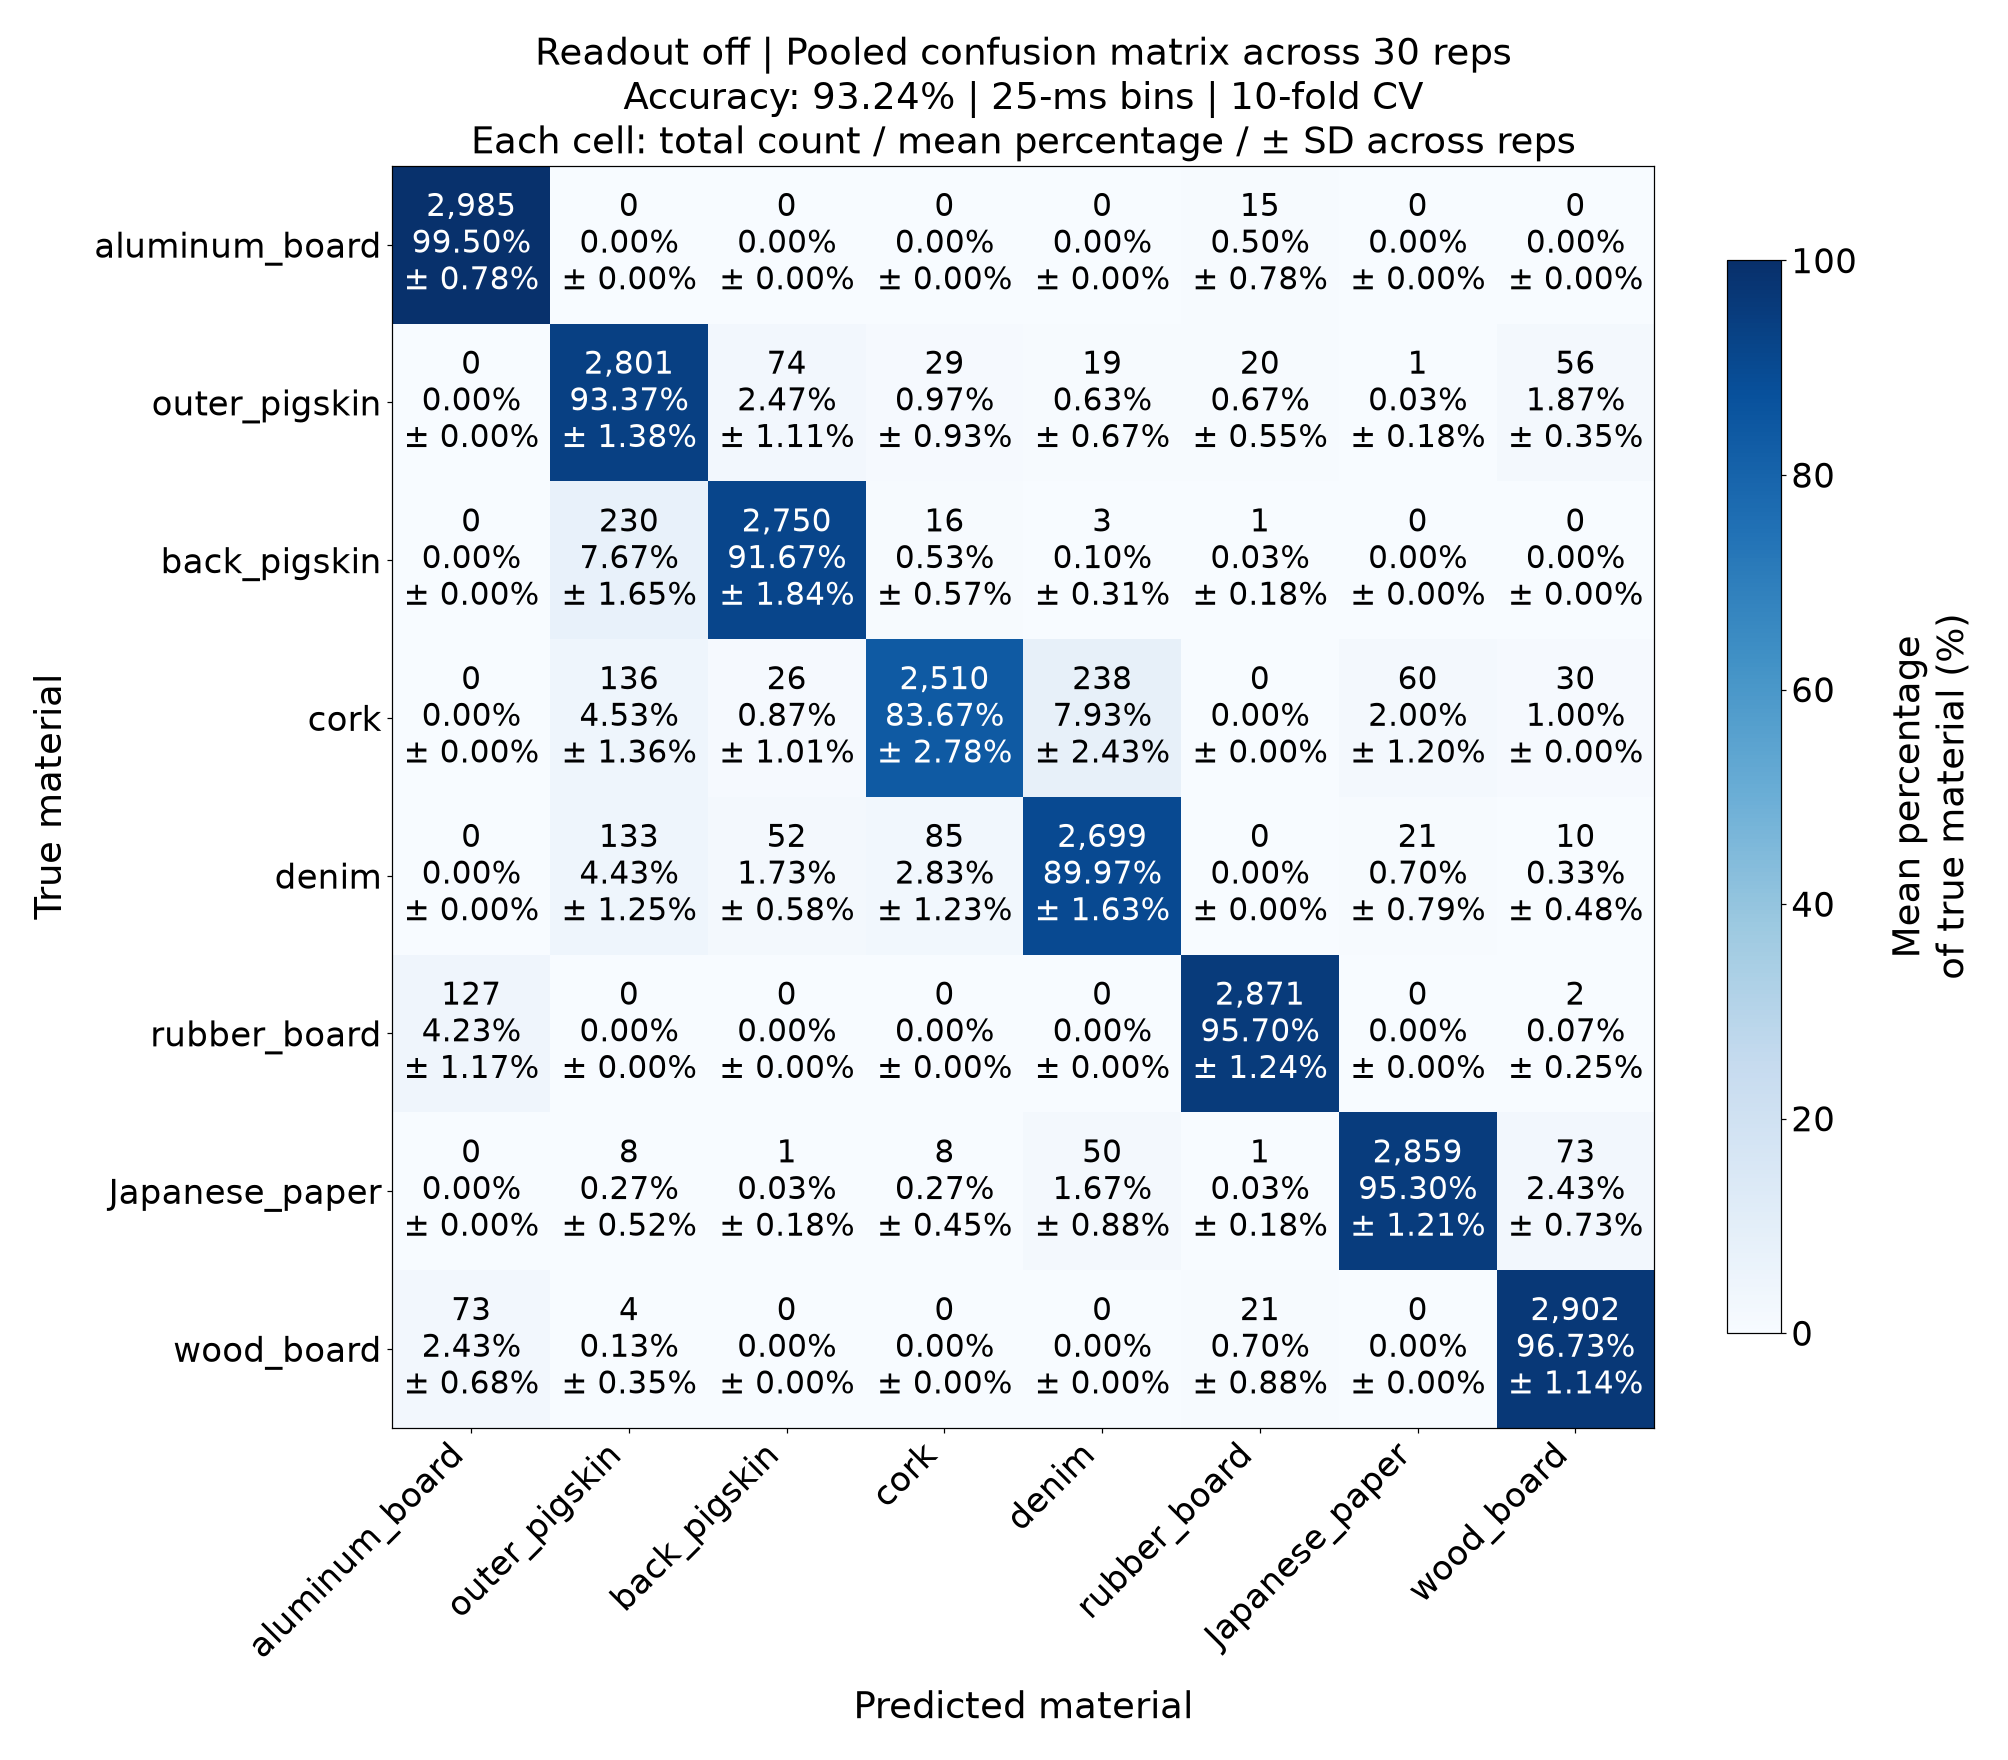

対象rep：[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30]
合計評価数：24,000（同じ元試行でもrepごとに別の評価として集計）
合算正答率：93.237%
rep正答率の平均：93.237%、SD：0.488ポイント


In [1]:
# Readout offの各repの混同行列を合算する（分類の再実行・結果ファイルの保存はしない）。
from pathlib import Path
from zipfile import ZipFile
from xml.etree import ElementTree as ET
import posixpath
import sys
import numpy as np
import matplotlib.pyplot as plt

# ノートブックをLSM直下・h_analysis・研究コード直下のいずれから開いても探す。
project_root = next(
    (root for parent in (Path.cwd(), *Path.cwd().parents)
     for root in (parent, parent / "LSM")
     if (root / "d_tools" / "evaluation_excel.py").is_file()), None
)
if project_root is None:
    raise FileNotFoundError("LSMフォルダからノートブックを開いてください。")
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
from d_tools.evaluation_excel import load_classification_results

# Noneなら保存済みの全repを使用。例：[1, 2, 3, 4, 5]で対象を限定できる。
REPS = None
BIN_MS = 25.0
# 結合確率・gainを指定し、この条件のoff結果だけを集計する。
CONNECTION_FOLDER = "p_E_readout-0.11__g_e_out-0.2706"
results_root = project_root / "g_tactile_results" / "readout_run" / CONNECTION_FOLDER / "off"


def read_confusion_counts(workbook_path, block_index):
    """指定した評価時間窓の8素材の個数を、Excelのconf_8clsシートから読む。"""
    ns = {"s": "http://schemas.openxmlformats.org/spreadsheetml/2006/main"}
    with ZipFile(workbook_path) as archive:
        workbook = ET.fromstring(archive.read("xl/workbook.xml"))
        sheet = next(s for s in workbook.findall("s:sheets/s:sheet", ns)
                     if s.get("name") == "conf_8cls")
        relations = {r.get("Id"): r.get("Target") for r in ET.fromstring(
            archive.read("xl/_rels/workbook.xml.rels"))}
        target = relations[sheet.get("{http://schemas.openxmlformats.org/officeDocument/2006/relationships}id")]
        target = target.lstrip("/") if target.startswith("/") else posixpath.normpath(posixpath.join("xl", target))
        cells = {c.get("r"): c for c in ET.fromstring(archive.read(target)).findall("s:sheetData/s:row/s:c", ns)}
        counts = np.array([[float(cells[f"{col}{row}"].find("s:v", ns).text)
                            for col in "BCDEFGHI"]
                           for row in range(2 + 12 * block_index, 10 + 12 * block_index)])
    if np.any(counts < 0) or not np.all(np.isfinite(counts)) or not np.all(counts == np.floor(counts)):
        raise ValueError(f"混同行列の個数が不正です：{workbook_path}")
    return counts.astype(np.int64)


# 同一の素材順・時間窓・分割数の結果だけを合算する。
rep_dirs = sorted((p for p in results_root.glob("rep*")
                   if p.is_dir() and p.name[3:].isdigit()), key=lambda p: int(p.name[3:]))
if REPS is not None:
    missing = set(REPS) - {int(p.name[3:]) for p in rep_dirs}
    if missing:
        raise FileNotFoundError(f"見つからないrep：{sorted(missing)}")
    rep_dirs = [p for p in rep_dirs if int(p.name[3:]) in REPS]
combined_counts = np.zeros((8, 8), dtype=np.int64)
used_reps, per_rep_accuracies = [], []
# 各repの行正規化割合を保持する。
per_rep_percentages = []
materials, folds = None, None
for rep_dir in rep_dirs:
    workbook_path = rep_dir / "test" / "eval" / "classification.xlsx"
    if not workbook_path.is_file():
        print(f"未完了のためスキップ：{rep_dir.name}")
        continue
    metadata = load_classification_results(workbook_path)
    if metadata is None:
        raise ValueError(f"評価条件を読み込めません：{workbook_path}")
    conditions = [i for i, value in enumerate(metadata["T_n_ms"])
                  if np.isclose(float(value), BIN_MS)]
    if len(conditions) != 1:
        raise ValueError(f"{rep_dir.name}に{BIN_MS:g} msの評価が一つだけ存在する必要があります。")
    if materials is None:
        materials, folds = metadata["materials"], metadata["folds"]
    if metadata["materials"] != materials or metadata["folds"] != folds:
        raise ValueError(f"素材順または分割数が異なります：{rep_dir.name}")
    counts = read_confusion_counts(workbook_path, conditions[0])
    if counts.sum() == 0 or np.any(counts.sum(axis=1) == 0):
        raise ValueError(f"評価個数が空です：{rep_dir.name}")
    accuracy = np.trace(counts) / counts.sum()
    summary = next(s for s in metadata["summary"] if np.isclose(float(s["T_n_ms"]), BIN_MS))
    if not np.isclose(accuracy, summary["accuracy"]):
        raise ValueError(f"個数と記録済み正答率が一致しません：{rep_dir.name}")
    per_rep_percentages.append(counts / counts.sum(axis=1, keepdims=True) * 100)
    combined_counts += counts
    used_reps.append(int(rep_dir.name[3:]))
    per_rep_accuracies.append(accuracy * 100)
if not used_reps:
    raise FileNotFoundError(f"集計できる評価結果がありません：{results_root}")

# 色は正解素材ごとの割合。各マスに合算個数と割合を併記する。
row_percent = np.mean(per_rep_percentages, axis=0)
# 各マスについて、rep間の標本標準偏差を計算する。
cell_sd_percent = (np.std(per_rep_percentages, axis=0, ddof=1)
                   if len(used_reps) > 1 else np.full((8, 8), np.nan))
pooled_accuracy = np.trace(combined_counts) / combined_counts.sum() * 100
fig, ax = plt.subplots(figsize=(20, 16), layout="constrained")
image = ax.imshow(row_percent, cmap="Blues", vmin=0, vmax=100)
for row in range(8):
    for col in range(8):
        ax.text(col, row, f"{combined_counts[row, col]:,}\n"
                + (f"{row_percent[row, col]:.2f}%\n\u00b1 {cell_sd_percent[row, col]:.2f}%"
                   if len(used_reps) > 1 else f"{row_percent[row, col]:.2f}% (SD: N/A)"),
                ha="center", va="center", fontsize=20,
                color="white" if row_percent[row, col] >= 50 else "black")
ax.set_xticks(range(8), materials, rotation=45, ha="right")
ax.set_yticks(range(8), materials)
ax.set_xlabel("Predicted material", fontsize=24, labelpad=16)
ax.set_ylabel("True material", fontsize=24, labelpad=16)
ax.set_title(f"Readout off | Pooled confusion matrix across {len(used_reps)} reps\n"
             f"Accuracy: {pooled_accuracy:.2f}% | {BIN_MS:g}-ms bins | {folds}-fold CV\n"
             "Each cell: total count / mean percentage / \u00b1 SD across reps")
ax.tick_params(axis="both", labelsize=22)
ax.title.set_fontsize(24)
# カラーバーの説明を短い2行に分け、周囲の余白を確保する。
colorbar = fig.colorbar(image, ax=ax, fraction=0.045, pad=0.04, shrink=0.85)
colorbar.set_label("Mean percentage\nof true material (%)", fontsize=24, labelpad=20)
colorbar.ax.tick_params(labelsize=22)
fig.get_layout_engine().set(w_pad=0.3, h_pad=0.3)
plt.show()
print(f"対象rep：{used_reps}")
print(f"合計評価数：{combined_counts.sum():,}（同じ元試行でもrepごとに別の評価として集計）")
print(f"合算正答率：{pooled_accuracy:.3f}%")
print(f"rep正答率の平均：{np.mean(per_rep_accuracies):.3f}%"
      + (f"、SD：{np.std(per_rep_accuracies, ddof=1):.3f}ポイント" if len(used_reps) > 1 else ""))


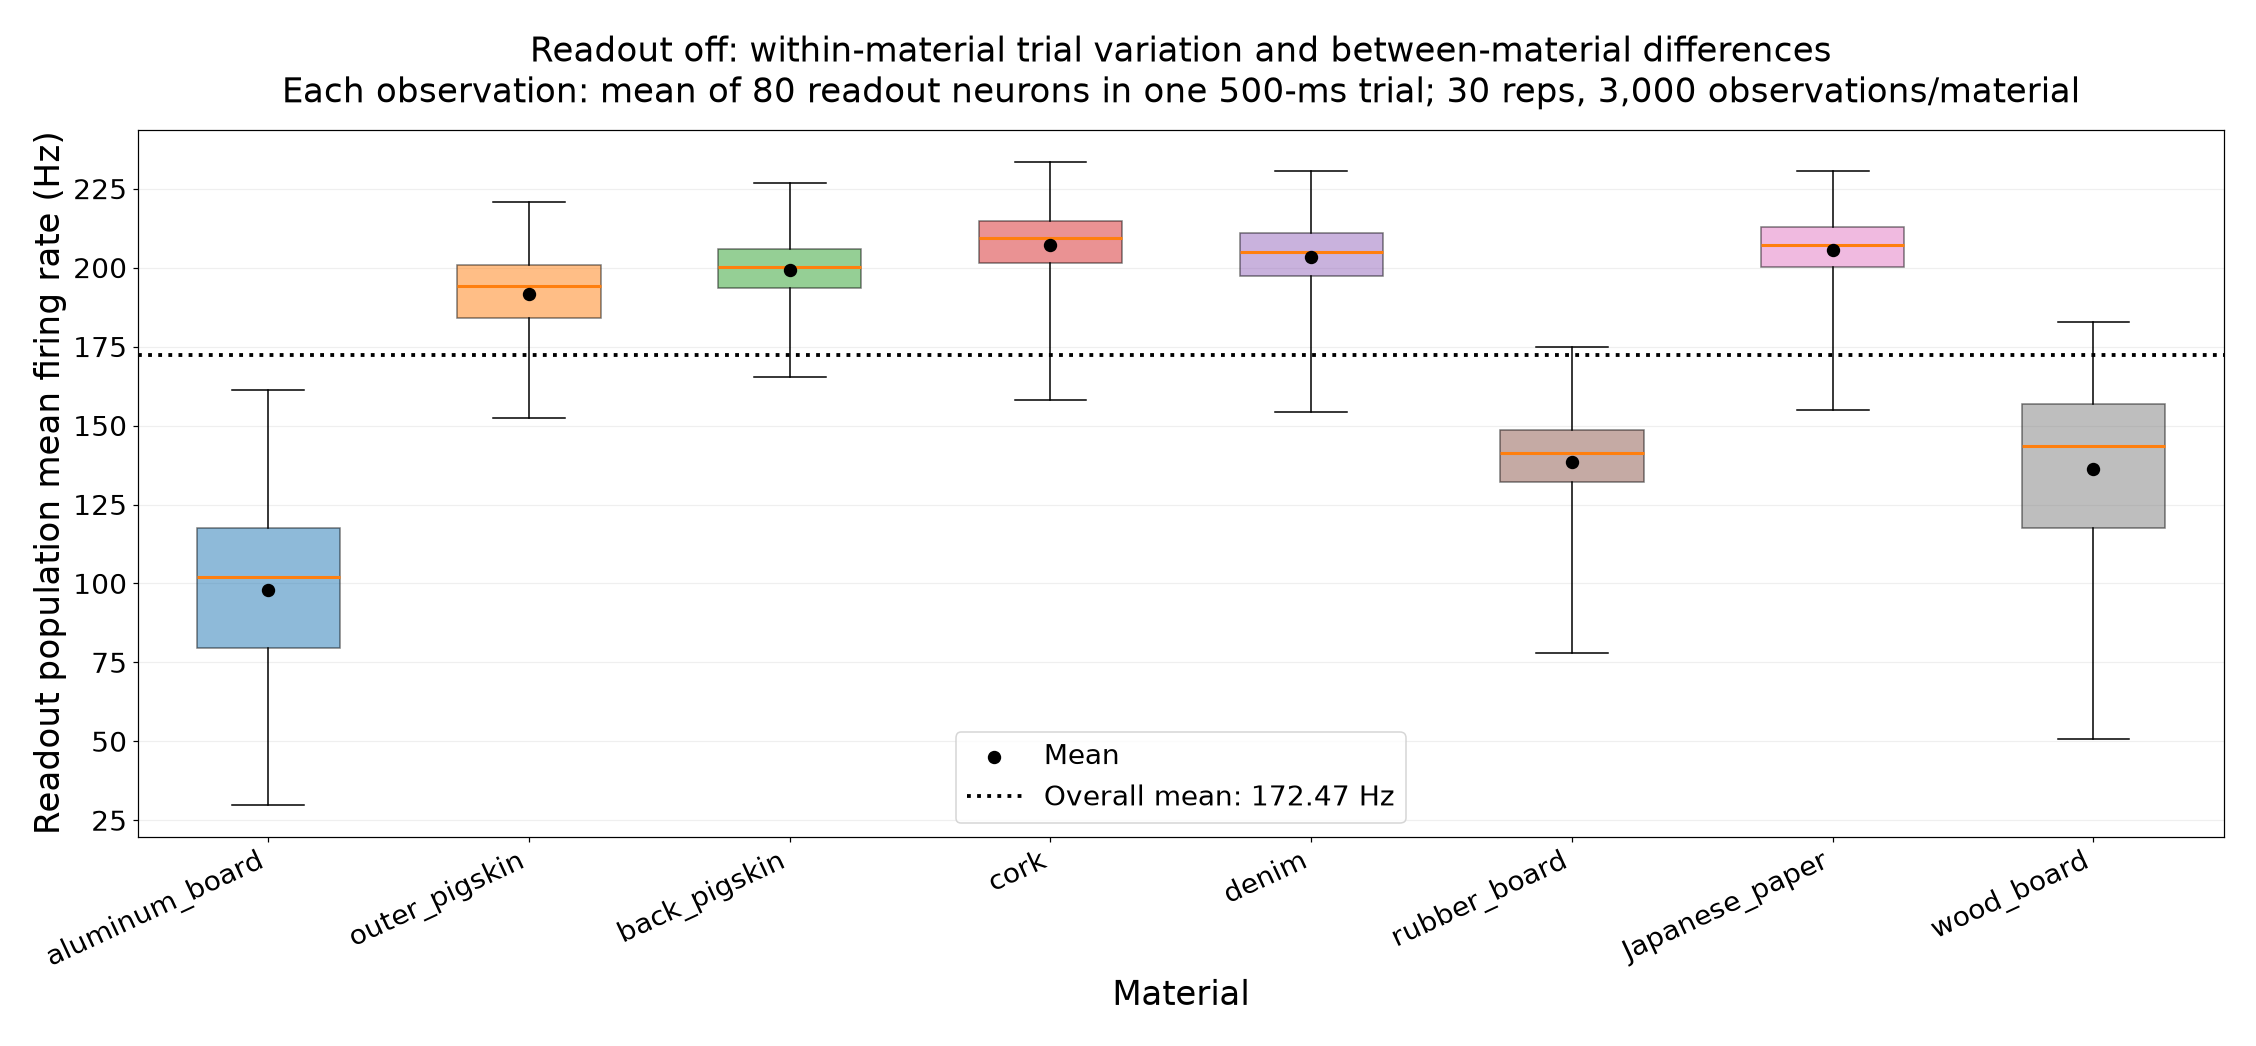

箱：第1～第3四分位、橙線：中央値、ひげ：最小～最大、黒点：平均
各repの試行数/素材：[100]
aluminum_board: 平均 97.904 Hz、SD 26.366 Hz、最小 29.950 Hz、最大 161.400 Hz
outer_pigskin: 平均 191.551 Hz、SD 12.493 Hz、最小 152.375 Hz、最大 220.775 Hz
back_pigskin: 平均 199.165 Hz、SD 9.684 Hz、最小 165.475 Hz、最大 226.950 Hz
cork: 平均 207.253 Hz、SD 11.088 Hz、最小 158.000 Hz、最大 233.475 Hz
denim: 平均 203.407 Hz、SD 10.561 Hz、最小 154.275 Hz、最大 230.625 Hz
rubber_board: 平均 138.524 Hz、SD 15.096 Hz、最小 77.950 Hz、最大 174.875 Hz
Japanese_paper: 平均 205.554 Hz、SD 10.521 Hz、最小 154.925 Hz、最大 230.725 Hz
wood_board: 平均 136.371 Hz、SD 25.380 Hz、最小 50.775 Hz、最大 182.825 Hz


In [2]:
# 各試行の出力層ニューロンの平均発火率を、素材別に表示する。
# 先頭セルと同じrepを使用。1観測は「1 repの1試行の出力層ニューロン平均」。
from d_tools.recording_io import read_record

if "used_reps" not in globals():
    raise RuntimeError("先に一番上の混同行列のセルを実行してください。")

material_trial_rates = [[] for _ in materials]
trial_counts_by_rep = []
reference_layers = None
reference_duration_ms = None
for rep in used_reps:
    test_dir = results_root / f"rep{rep}" / "test"
    record_info = read_record(test_dir / "rec" / "recording.npz")
    if record_info["materials"] != materials:
        raise ValueError(f"素材の順序が異なります：rep{rep}")
    if record_info["axis_order"] != ["material", "trial", "neuron", "time_bin"]:
        raise ValueError(f"記録配列の軸の順序が異なります：rep{rep}")
    if record_info["value"] != "spike count per bin":
        raise ValueError(f"発火数の記録ではありません：rep{rep}")
    # 出力層の全ニューロンを、保存された群の順に連結して集計する。
    layers = [int(size) for size in record_info["readout_layers"]]
    offset = sum(layers)
    neuron_ids = list(range(offset))
    if not neuron_ids:
        raise ValueError(f"出力層のニューロンがありません：rep{rep}")
    spike_counts = np.load(test_dir / "rec" / "readout" / f"sout_rec_rep{rep}.npy",
                           mmap_mode="r", allow_pickle=False)
    try:
        if spike_counts.ndim != 4 or spike_counts.shape[0] != len(materials) or spike_counts.shape[2] != offset:
            raise ValueError(f"記録配列の形が不正です：rep{rep}")
        duration_ms = spike_counts.shape[-1] * float(record_info["bin_width_ms"])
        if reference_layers is None:
            reference_layers = layers
            reference_duration_ms = duration_ms
        if layers != reference_layers or not np.isclose(duration_ms, reference_duration_ms):
            raise ValueError(f"ニューロン数または試行時間が異なります：rep{rep}")
        trial_counts_by_rep.append(spike_counts.shape[1])
        for material_index in range(len(materials)):
            # 時間方向の発火数合計 / 試行秒数を、全出力層ニューロンで平均してHzにする。
            trial_rates_hz = (spike_counts[material_index][:, neuron_ids, :]
                              .sum(axis=(1, 2), dtype=np.float64)
                              / len(neuron_ids) / (duration_ms / 1000.0))
            material_trial_rates[material_index].append(trial_rates_hz)
    finally:
        spike_counts._mmap.close()

# repごとの試行をまとめる。同じ元試行でもrepが異なれば別の観測として扱う。
material_trial_rates = [np.concatenate(values) for values in material_trial_rates]
mean_rates_hz = np.array([values.mean() for values in material_trial_rates])
# 素材ごとの観測数も反映し、全素材・全rep・全試行の平均を求める。
overall_rate_hz = float(np.concatenate(material_trial_rates).mean())
fig, ax = plt.subplots(figsize=(20, 9), layout="constrained")
boxes = ax.boxplot(material_trial_rates, tick_labels=materials, patch_artist=True,
                   showfliers=False, whis=(0, 100), widths=0.55,
                   medianprops={"color": "tab:orange", "linewidth": 2})
for box, color in zip(boxes["boxes"], plt.get_cmap("tab10").colors):
    box.set_facecolor(color)
    box.set_alpha(0.5)
ax.scatter(np.arange(1, len(materials) + 1), mean_rates_hz,
           color="black", s=60, label="Mean", zorder=3)
ax.axhline(overall_rate_hz, color="black", linestyle=":", linewidth=2.5,
           label=f"Overall mean: {overall_rate_hz:.2f} Hz", zorder=2)
ax.set_ylabel("Readout population mean firing rate (Hz)", fontsize=22)
ax.set_xlabel("Material", fontsize=22)
ax.set_title("Readout off: within-material trial variation and between-material differences\n"
             f"Each observation: mean of {len(neuron_ids)} readout neurons in one {reference_duration_ms:g}-ms trial; "
             f"{len(used_reps)} reps, {len(material_trial_rates[0]):,} observations/material",
             fontsize=22, pad=18)
ax.tick_params(axis="both", labelsize=18)
plt.setp(ax.get_xticklabels(), rotation=25, ha="right")
ax.grid(axis="y", alpha=0.2)
ax.legend(fontsize=18)
plt.show()
print("箱：第1～第3四分位、橙線：中央値、ひげ：最小～最大、黒点：平均")
print(f"各repの試行数/素材：{sorted(set(trial_counts_by_rep))}")
for material, values in zip(materials, material_trial_rates):
    print(f"{material}: 平均 {values.mean():.3f} Hz、SD {values.std(ddof=1):.3f} Hz、"
          f"最小 {values.min():.3f} Hz、最大 {values.max():.3f} Hz")
